# Student Performance: What Drives GPA?

**Questions:** (1) Do students who study more earn higher GPAs? (2) Do students who attend more? (3) Looking at every factor together, what matters most, and how well can we predict GPA and flag students at risk?

**Data:** 2,392 students with study time, absences, tutoring, parental factors, activities, GPA and letter-grade class. **Tools:** Python, pandas, SciPy, scikit-learn, matplotlib.

## Key results

- **Absences are the dominant factor.** Each additional absence goes with about **0.10 lower GPA** (r = -0.92). Students with 0-4 absences average a **3.16** GPA; students with 25-29 absences average **0.69**.
- **Study time helps, but modestly.** About **+0.03 GPA per weekly study hour** (roughly +0.3 GPA for 10 more hours; r = 0.18). Alone it explains about 3% of the variation in GPA.
- **Other factors each add a little:** tutoring (+0.25 GPA), parental support (+0.15 per level), extracurriculars (+0.19) and sports (+0.19). Age, gender and parental education show no clear effect.
- **GPA is highly predictable here.** A linear regression predicts GPA for unseen students with an error of about **0.20 GPA points** (R-squared 0.95), against 0.91 for guessing the average.
- **At-risk flag (GPA below 2.0):** absences alone identify at-risk students with **92% accuracy**; study time alone manages 55%, barely better than the 53% majority-class baseline.
- **Caveat:** the data looks synthetic (see section 2), so these results describe this dataset rather than real students.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, f1_score, mean_absolute_error,
    mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# One small palette, used consistently: teal = main series, rose = negative effect, grey = context.
TEAL, ROSE, AMBER, GREY, INK = "#1f6f8b", "#b04a5a", "#e39b2d", "#9aa7af", "#17262f"

plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#66757f", "axes.labelcolor": "#4b5d68", "xtick.color": "#4b5d68",
    "ytick.color": "#4b5d68", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6ecef", "grid.linewidth": 0.8, "figure.dpi": 100,
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.3f}".format


def save_fig(fig, name):
    """Save a figure into figures/ (used by the README)."""
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight")


def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

## 2. Load and audit the data

Before any analysis, check that the data is what it claims to be: types, missing values, duplicates, ranges, and whether the columns agree with each other.

In [2]:
df = pd.read_csv("data/student_performance.csv")
print(f"{df.shape[0]:,} students, {df.shape[1]} columns")
df.head()

2,392 students, 12 columns


,StudentID,Age,Gender,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,GPA,GradeClass
0,1001,17,1,2,19.834,7,1,2,0,0,2.929,2
1,1002,18,0,1,15.409,0,0,1,0,0,3.043,1
2,1003,15,0,3,4.211,26,0,2,0,0,0.113,4
3,1004,17,1,3,10.029,14,0,3,1,0,2.054,3
4,1005,17,1,2,4.672,17,1,3,0,0,1.288,4


| Column | Meaning |
|---|---|
| `StudentID` | Identifier (not used in modeling) |
| `Age`, `Gender` | Age 15-18; gender coded 0/1 |
| `ParentalEducation`, `ParentalSupport` | Ordinal scores, 0-4 (higher = more) |
| `StudyTimeWeekly` | Hours studied per week |
| `Absences` | Number of absences in the year |
| `Tutoring`, `Extracurricular`, `Sports` | 1 = yes, 0 = no |
| `GPA` | Grade point average on a 0-4 scale (**target**) |
| `GradeClass` | Letter-grade category, 0 (A) to 4 (F) |

In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique values": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
print(f"Duplicate rows: {df.duplicated().sum()}   Duplicate IDs: {df['StudentID'].duplicated().sum()}")
audit

Duplicate rows: 0   Duplicate IDs: 0


,dtype,missing,unique values,min,max
StudentID,int64,0,2392,"1,001.000","3,392.000"
Age,int64,0,4,15.000,18.000
Gender,int64,0,2,0.000,1.000
ParentalEducation,int64,0,5,0.000,4.000
StudyTimeWeekly,float64,0,2392,0.001,19.978
Absences,int64,0,30,0.000,29.000
Tutoring,int64,0,2,0.000,1.000
ParentalSupport,int64,0,5,0.000,4.000
Extracurricular,int64,0,2,0.000,1.000
Sports,int64,0,2,0.000,1.000


No missing values, duplicates, or out-of-range entries. One more check: `GradeClass` should be a simple function of `GPA` (A is 3.5 and up, B is 3.0-3.5, and so on). If it is, it carries no new information and must never be used to predict GPA.

In [4]:
# Expected letter-grade class implied by GPA: 0 (A) >= 3.5, 1 (B) >= 3.0, 2 (C) >= 2.5, 3 (D) >= 2.0, 4 (F) < 2.0
expected_class = pd.cut(df["GPA"], bins=[-np.inf, 2.0, 2.5, 3.0, 3.5, np.inf],
                        labels=[4, 3, 2, 1, 0], right=False).astype(int)
agreement = (expected_class == df["GradeClass"]).mean()
print(f"GradeClass matches the GPA-implied class for {agreement:.1%} of students "
      f"({(expected_class != df['GradeClass']).sum()} mismatches)")
pd.crosstab(df["GradeClass"], expected_class, rownames=["GradeClass (recorded)"], colnames=["Class implied by GPA"])

GradeClass matches the GPA-implied class for 93.0% of students (168 mismatches)


Class implied by GPA,0,1,2,3,4
GradeClass (recorded),,,,,
0,71,1,10,9,16
1,2,229,3,7,28
2,2,3,360,9,17
3,1,7,7,375,24
4,1,4,5,12,1189


`GradeClass` agrees with GPA for most students but not all, so it is a noisy label rather than an exact derivative. To avoid leakage, **it is excluded from every model below** and I use `GPA` directly.

One more thing worth knowing about the data itself: the predictors are almost perfectly uncorrelated with each other, and study time and absences are close to uniformly distributed. Real student records are rarely this clean.

In [5]:
predictors = ["Age", "Gender", "ParentalEducation", "StudyTimeWeekly", "Absences",
              "Tutoring", "ParentalSupport", "Extracurricular", "Sports"]
corr = df[predictors].corr().to_numpy()
off_diag = np.abs(corr[~np.eye(len(predictors), dtype=bool)])
print(f"Average |correlation| between predictors: {off_diag.mean():.3f}  (largest: {off_diag.max():.3f})")
for col in ["StudyTimeWeekly", "Absences"]:
    scaled = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
    ks = stats.kstest(scaled, "uniform")
    print(f"{col}: KS distance from a uniform distribution = {ks.statistic:.3f}")

Average |correlation| between predictors: 0.016  (largest: 0.046)
StudyTimeWeekly: KS distance from a uniform distribution = 0.030
Absences: KS distance from a uniform distribution = 0.031


**What this means for the project:** the data looks synthetic (generated), or at least heavily cleaned. Findings below describe *this dataset*; they should not be presented as measured facts about real students. I keep this caveat in the README and the conclusions.

## 3. Describe the data

The original version of this project reported the *mode* of study time and GPA. For continuous measurements the mode is not meaningful (every value is almost unique), so the summary below uses mean, median, spread and range instead.

In [6]:
numeric = ["StudyTimeWeekly", "Absences", "GPA"]
summary_stats = df[numeric].agg(["mean", "median", "std", "min", "max"]).T
summary_stats["IQR"] = df[numeric].quantile(0.75) - df[numeric].quantile(0.25)
summary_stats

,mean,median,std,min,max,IQR
StudyTimeWeekly,9.772,9.705,5.653,0.001,19.978,9.365
Absences,14.541,15.000,8.467,0.000,29.000,15.000
GPA,1.906,1.893,0.915,0.000,4.000,1.447


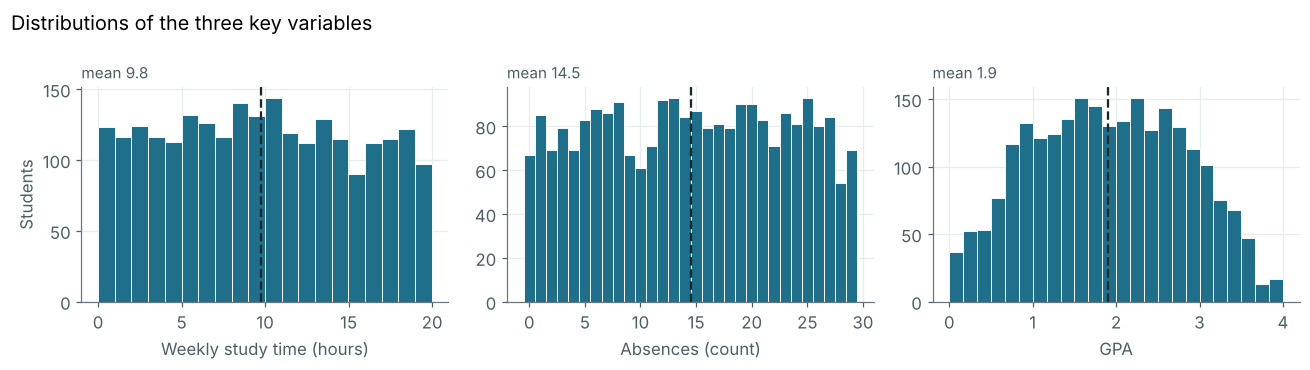

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
specs = [("StudyTimeWeekly", "Weekly study time (hours)", TEAL, 20),
         ("Absences", "Absences (count)", TEAL, np.arange(-0.5, 30.5, 1)),  # one bar per whole absence
         ("GPA", "GPA", TEAL, 24)]
for ax, (col, label, color, bins) in zip(axes, specs):
    ax.hist(df[col], bins=bins, color=color, edgecolor="white", linewidth=0.6)
    ax.axvline(df[col].mean(), color=INK, lw=1.5, ls="--")
    ax.set_xlabel(label)
    ax.set_title(f"mean {df[col].mean():.1f}", loc="left", fontsize=10, color="#4b5d68")
axes[0].set_ylabel("Students")
fig.suptitle("Distributions of the three key variables", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "01_distributions.png")
plt.show()

Study time and absences are spread fairly evenly across their ranges, while GPA is roughly symmetric around 1.9. More than half of students (about 53%) have a GPA below 2.0, a fact that matters for the at-risk model in section 7.

## 4. Hypothesis 1: do students who study more earn higher GPAs?

I test the relationship three ways: the correlation (with a confidence interval), the slope of a simple regression (GPA points gained per extra weekly study hour), and a plain comparison of group averages.

In [8]:
def pearson_ci(x, y, alpha=0.05):
    """Pearson r with a Fisher-z confidence interval and p-value."""
    r, p = stats.pearsonr(x, y)
    z, se = np.arctanh(r), 1 / np.sqrt(len(x) - 3)
    half = stats.norm.ppf(1 - alpha / 2) * se
    return r, np.tanh(z - half), np.tanh(z + half), p


def relationship(col):
    x, y = df[col], df["GPA"]
    r, lo, hi, p = pearson_ci(x, y)
    fit = stats.linregress(x, y)
    half = stats.t.ppf(0.975, len(x) - 2) * fit.stderr
    return {
        "Pearson r": r, "95% CI for r": f"[{lo:.2f}, {hi:.2f}]", "p-value": fmt_p(p),
        "Spearman rho": stats.spearmanr(x, y)[0],
        "GPA change per unit": fit.slope, "95% CI for slope": f"[{fit.slope - half:.3f}, {fit.slope + half:.3f}]",
        "R-squared": fit.rvalue ** 2,
    }


def quartile_gap(col):
    """Mean GPA of the top vs bottom quartile of a variable, with a Welch t-test and effect size."""
    low_cut, high_cut = df[col].quantile([0.25, 0.75])
    low = df.loc[df[col] <= low_cut, "GPA"]
    high = df.loc[df[col] >= high_cut, "GPA"]
    t, p = stats.ttest_ind(high, low, equal_var=False)
    pooled_sd = np.sqrt((low.var() + high.var()) / 2)
    return {"Bottom quartile mean GPA": low.mean(), "Top quartile mean GPA": high.mean(),
            "Difference (top - bottom)": high.mean() - low.mean(),
            "Cohen's d": (high.mean() - low.mean()) / pooled_sd, "Welch p-value": fmt_p(p)}


def relationship_figure(col, xlabel, bin_edges, bin_labels, color, title, fname):
    """Left: every student with the fitted line. Right: average GPA by group with 95% intervals."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
    ax1.scatter(df[col], df["GPA"], s=9, alpha=0.3, color=GREY, edgecolor="none")
    fit = stats.linregress(df[col], df["GPA"])
    xs = np.array([df[col].min(), df[col].max()])
    ax1.plot(xs, fit.intercept + fit.slope * xs, color=color, lw=2.8)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("GPA")
    ax1.set_title(f"r = {fit.rvalue:.2f}", loc="left", fontsize=10, color="#4b5d68")

    groups = df.groupby(pd.cut(df[col], bin_edges, include_lowest=True), observed=True)["GPA"].agg(["mean", "sem", "count"])
    groups.index = bin_labels
    pos = np.arange(len(groups))
    ax2.bar(pos, groups["mean"], yerr=1.96 * groups["sem"], color=color, width=0.65, capsize=3,
            error_kw={"ecolor": INK, "lw": 1})
    for i, m in enumerate(groups["mean"]):
        ax2.text(i, m + 0.14, f"{m:.2f}", ha="center", fontsize=10, color=INK)
    ax2.set_xticks(pos); ax2.set_xticklabels(bin_labels)
    ax2.set_xlabel(xlabel); ax2.set_ylabel("Average GPA"); ax2.set_ylim(0, 4)
    ax2.grid(axis="x", visible=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    save_fig(fig, fname)
    plt.show()
    return groups


pd.DataFrame({c: relationship(c) for c in ["StudyTimeWeekly", "Absences"]}).T

,Pearson r,95% CI for r,p-value,Spearman rho,GPA change per unit,95% CI for slope,R-squared
StudyTimeWeekly,0.179,"[0.14, 0.22]",< 0.001,0.169,0.029,"[0.023, 0.035]",0.032
Absences,-0.919,"[-0.93, -0.91]",< 0.001,-0.925,-0.099,"[-0.101, -0.098]",0.845


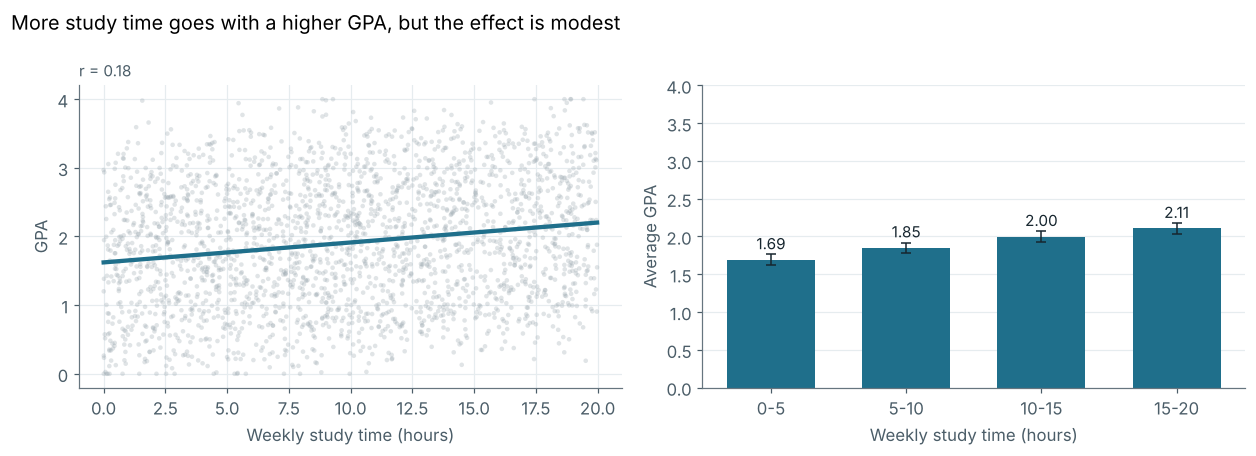

,mean,sem,count
0-5,1.692,0.037,595
5-10,1.849,0.036,643
10-15,1.999,0.036,619
15-20,2.106,0.039,535


In [9]:
groups_study = relationship_figure(
    "StudyTimeWeekly", "Weekly study time (hours)", [0, 5, 10, 15, 20], ["0-5", "5-10", "10-15", "15-20"],
    TEAL, "More study time goes with a higher GPA, but the effect is modest", "02_study_time_vs_gpa.png")
groups_study

In [10]:
pd.DataFrame({"Study time (top vs bottom quartile)": quartile_gap("StudyTimeWeekly")}).T

,Bottom quartile mean GPA,Top quartile mean GPA,Difference (top - bottom),Cohen's d,Welch p-value
Study time (top vs bottom quartile),1.695,2.107,0.412,0.462,< 0.001


## 5. Hypothesis 2: do students who attend more earn higher GPAs?

Attendance is measured here by its opposite, the number of **absences**, so a negative relationship with GPA is the expected direction.

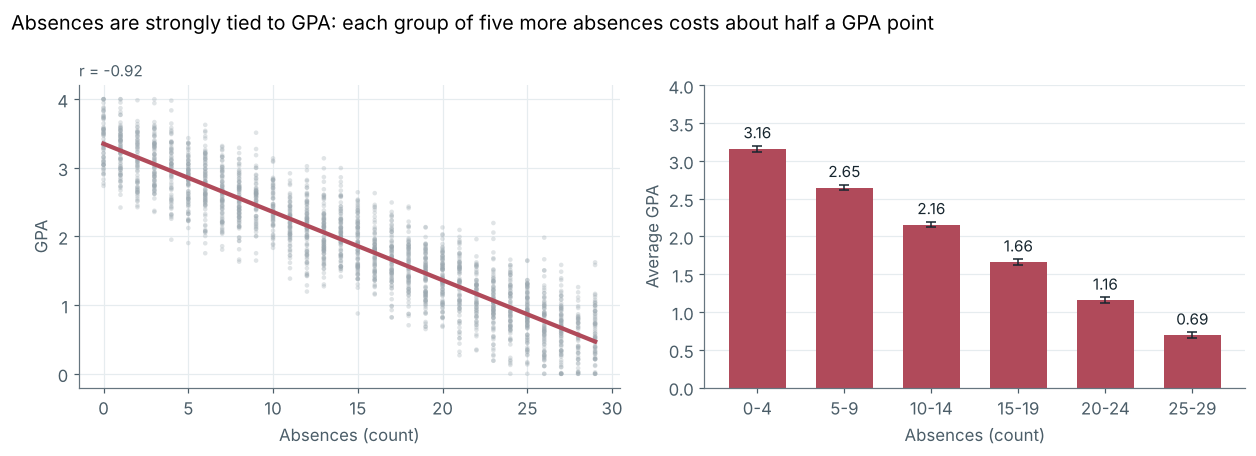

,mean,sem,count
0-4,3.161,0.020,369
5-9,2.647,0.018,415
10-14,2.156,0.019,401
15-19,1.662,0.019,416
20-24,1.156,0.020,411
25-29,0.694,0.019,380


In [11]:
groups_abs = relationship_figure(
    "Absences", "Absences (count)", [-1, 4, 9, 14, 19, 24, 29], ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29"],
    ROSE, "Absences are strongly tied to GPA: each group of five more absences costs about half a GPA point",
    "03_absences_vs_gpa.png")
groups_abs

In [12]:
pd.DataFrame({"Absences (top vs bottom quartile)": quartile_gap("Absences")}).T

,Bottom quartile mean GPA,Top quartile mean GPA,Difference (top - bottom),Cohen's d,Welch p-value
Absences (top vs bottom quartile),2.982,0.822,-2.160,-5.094,< 0.001


## 6. Looking at everything together

Study time and absences could be tangled up with other factors such as tutoring or parental support, so I fit one multiple regression with all nine predictors. Standard errors are heteroskedasticity-robust (HC3). To compare factors measured in different units, the chart shows each effect **per one standard deviation** of the predictor.

In [13]:
FEATURES = ["StudyTimeWeekly", "Absences", "Tutoring", "ParentalSupport", "ParentalEducation",
            "Extracurricular", "Sports", "Age", "Gender"]
LABELS = {"StudyTimeWeekly": "Weekly study time", "Absences": "Absences", "Tutoring": "Tutoring",
          "ParentalSupport": "Parental support", "ParentalEducation": "Parental education",
          "Extracurricular": "Extracurriculars", "Sports": "Sports", "Age": "Age", "Gender": "Gender"}


def ols(X, y):
    """Ordinary least squares with HC3 robust standard errors (numpy implementation)."""
    Xm = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    yv = y.to_numpy(dtype=float)
    n, k = Xm.shape
    xtx_inv = np.linalg.inv(Xm.T @ Xm)
    beta = xtx_inv @ Xm.T @ yv
    resid = yv - Xm @ beta
    leverage = np.einsum("ij,jk,ik->i", Xm, xtx_inv, Xm)
    scaled = Xm * (resid / (1 - leverage))[:, None]
    cov = xtx_inv @ (scaled.T @ scaled) @ xtx_inv
    se = np.sqrt(np.diag(cov))
    dof = n - k
    crit = stats.t.ppf(0.975, dof)
    r2 = 1 - resid @ resid / ((yv - yv.mean()) ** 2).sum()
    table = pd.DataFrame({
        "coef": beta, "robust SE": se, "t": beta / se, "p-value": 2 * stats.t.sf(np.abs(beta / se), dof),
        "CI low": beta - crit * se, "CI high": beta + crit * se,
    }, index=["Intercept"] + list(X.columns))
    return table, r2, 1 - (1 - r2) * (n - 1) / dof, resid, Xm @ beta


X_all, y_all = df[FEATURES], df["GPA"]
coef_table, r2, adj_r2, resid, fitted = ols(X_all, y_all)
print(f"R-squared = {r2:.3f}   adjusted R-squared = {adj_r2:.3f}   n = {len(df):,}")
coef_table.assign(**{"p-value": coef_table["p-value"].map(fmt_p)})

R-squared = 0.950   adjusted R-squared = 0.950   n = 2,392


,coef,robust SE,t,p-value,CI low,CI high
Intercept,2.628,0.065,40.195,< 0.001,2.500,2.756
StudyTimeWeekly,0.029,0.001,38.707,< 0.001,0.028,0.030
Absences,-0.100,0.000,-203.179,< 0.001,-0.101,-0.099
Tutoring,0.249,0.009,26.729,< 0.001,0.231,0.267
ParentalSupport,0.153,0.004,40.382,< 0.001,0.146,0.161
ParentalEducation,0.004,0.004,0.947,0.344,-0.004,0.013
Extracurricular,0.189,0.009,21.879,< 0.001,0.172,0.206
Sports,0.191,0.009,20.538,< 0.001,0.173,0.210
Age,-0.006,0.004,-1.569,0.117,-0.014,0.002
Gender,0.016,0.008,1.871,0.061,-0.001,0.032


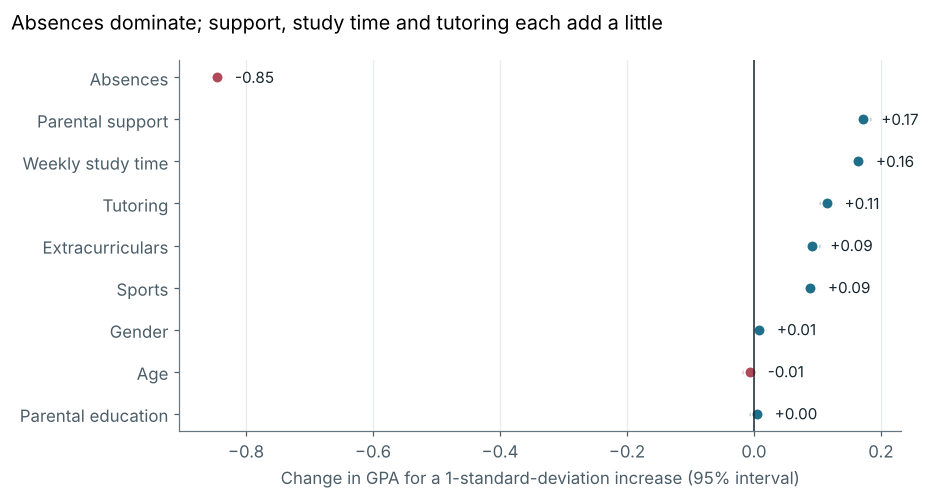

In [14]:
# Standardized effects: change in GPA (in GPA points) for a 1-standard-deviation change in the predictor
sd_x = X_all.std(ddof=1)
std_table = coef_table.drop(index="Intercept")[["coef", "CI low", "CI high"]].mul(sd_x, axis=0)
std_table = std_table.reindex(std_table["coef"].abs().sort_values().index)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, (name, row) in enumerate(std_table.iterrows()):
    color = TEAL if row["coef"] > 0 else ROSE
    ax.plot([row["CI low"], row["CI high"]], [i, i], color=color, lw=2.2)
    ax.plot(row["coef"], i, "o", color=color, ms=8, mec="white", mew=1.5)
    ax.text(row["CI high"] + 0.02, i, f"{row['coef']:+.2f}", va="center", fontsize=10, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(std_table))); ax.set_yticklabels([LABELS[n] for n in std_table.index])
ax.set_xlabel("Change in GPA for a 1-standard-deviation increase (95% interval)")
ax.grid(axis="y", visible=False)
fig.suptitle("Absences dominate; support, study time and tutoring each add a little", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "04_effects_per_sd.png")
plt.show()

In [15]:
# Does the study-time effect change once other factors are held fixed?
simple = stats.linregress(df["StudyTimeWeekly"], df["GPA"])
print(f"Study time, alone:              +{simple.slope:.3f} GPA per weekly hour")
print(f"Study time, all factors held:   +{coef_table.loc['StudyTimeWeekly', 'coef']:.3f} GPA per weekly hour")
print(f"Absences, alone:                {stats.linregress(df['Absences'], df['GPA']).slope:.3f} GPA per absence")
print(f"Absences, all factors held:     {coef_table.loc['Absences', 'coef']:.3f} GPA per absence")

# Multicollinearity check (variance inflation factors)
vif = {}
for col in FEATURES:
    others = [c for c in FEATURES if c != col]
    _, r2_col, *_ = ols(df[others], df[col])
    vif[col] = 1 / (1 - r2_col)
print(f"Largest VIF: {max(vif.values()):.2f} (values near 1 mean the predictors are not tangled together)")

Study time, alone:              +0.029 GPA per weekly hour
Study time, all factors held:   +0.029 GPA per weekly hour
Absences, alone:                -0.099 GPA per absence
Absences, all factors held:     -0.100 GPA per absence
Largest VIF: 1.01 (values near 1 mean the predictors are not tangled together)


Residual standard deviation: 0.204 GPA points


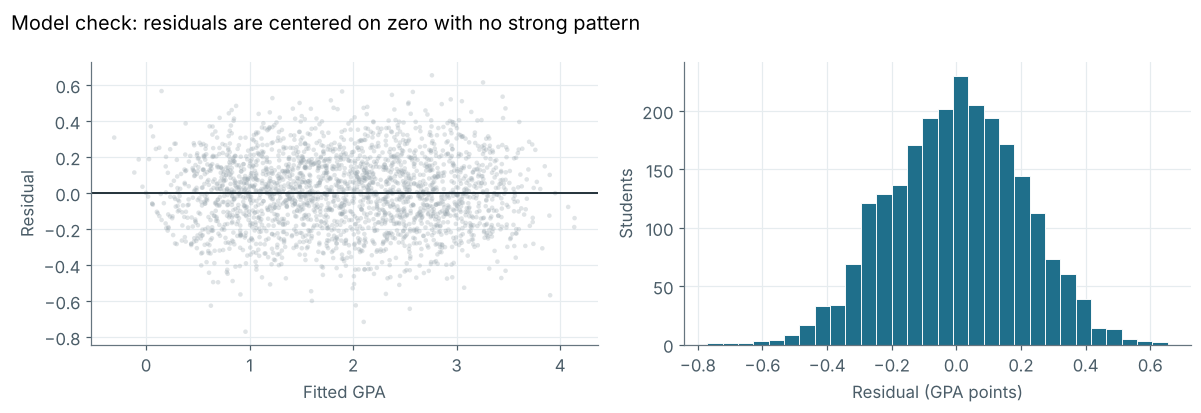

In [16]:
# Regression diagnostics: do the residuals look reasonable?
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.scatter(fitted, resid, s=9, alpha=0.3, color=GREY, edgecolor="none")
ax1.axhline(0, color=INK, lw=1.2)
ax1.set_xlabel("Fitted GPA"); ax1.set_ylabel("Residual")
ax2.hist(resid, bins=30, color=TEAL, edgecolor="white", linewidth=0.6)
ax2.set_xlabel("Residual (GPA points)"); ax2.set_ylabel("Students")
fig.suptitle("Model check: residuals are centered on zero with no strong pattern", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "05_residual_diagnostics.png")
plt.show()
print(f"Residual standard deviation: {resid.std(ddof=1):.3f} GPA points")

## 7. Prediction: how well can we forecast GPA, and flag students at risk?

The regression above explains patterns; here I test whether the patterns **generalize** to students the model has not seen. I hold out 20% of students, and compare a simple linear model with two more flexible models against a "just guess the average" baseline.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)

candidates = {
    "Average-GPA baseline": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
rows, fitted_models = [], {}
for name, model in candidates.items():
    cv_r2 = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    rows.append({"Model": name, "5-fold CV R-squared": cv_r2.mean(),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                 "Test MAE": mean_absolute_error(y_test, pred), "Test R-squared": r2_score(y_test, pred)})
results = pd.DataFrame(rows).set_index("Model")
results

,5-fold CV R-squared,Test RMSE,Test MAE,Test R-squared
Model,,,,
Average-GPA baseline,-0.003,0.910,0.766,-0.001
Linear regression,0.949,0.200,0.155,0.952
Random forest,0.925,0.247,0.192,0.926
Gradient boosting,0.942,0.216,0.167,0.944


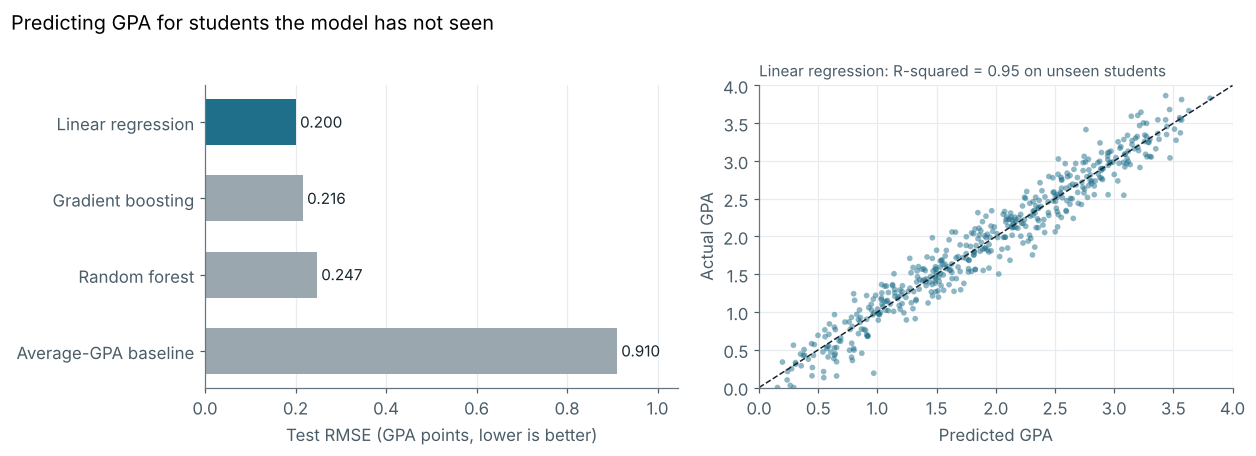

In [18]:
best_name = results["Test RMSE"].drop("Average-GPA baseline").idxmin()
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
order = results["Test RMSE"].sort_values(ascending=False)
ax1.barh(order.index, order.values, color=[TEAL if n == best_name else GREY for n in order.index], height=0.6)
for i, v in enumerate(order.values):
    ax1.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=10, color=INK)
ax1.set_xlabel("Test RMSE (GPA points, lower is better)"); ax1.grid(axis="y", visible=False)
ax1.set_xlim(0, order.max() * 1.15)
ax2.scatter(best_pred, y_test, s=14, alpha=0.5, color=TEAL, edgecolor="none")
ax2.plot([0, 4], [0, 4], color=INK, lw=1, ls="--")
ax2.set_xlim(0, 4); ax2.set_ylim(0, 4)
ax2.set_xlabel("Predicted GPA"); ax2.set_ylabel("Actual GPA")
ax2.set_title(f"{best_name}: R-squared = {r2_score(y_test, best_pred):.2f} on unseen students", loc="left", fontsize=10, color="#4b5d68")
fig.suptitle("Predicting GPA for students the model has not seen", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "06_gpa_prediction.png")
plt.show()

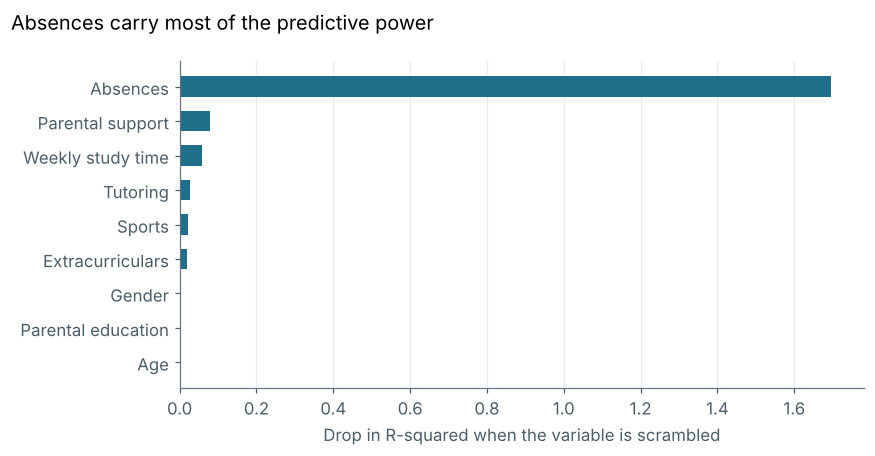

Absences            1.697
ParentalSupport     0.078
StudyTimeWeekly     0.059
Tutoring            0.028
Sports              0.021
Extracurricular     0.020
Gender              0.000
ParentalEducation   0.000
Age                 0.000
dtype: float64

In [19]:
# Which inputs does the best model rely on? (permutation importance on the held-out students)
imp = permutation_importance(best_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([LABELS[n] for n in importance.index], importance.values, color=TEAL, height=0.6)
ax.set_xlabel("Drop in R-squared when the variable is scrambled")
ax.grid(axis="y", visible=False)
fig.suptitle("Absences carry most of the predictive power", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "07_permutation_importance.png")
plt.show()
# A drop above 1.0 means the model does worse than simply guessing the average GPA once that input is scrambled.
importance.sort_values(ascending=False).round(3)

### Flagging at-risk students

A practical use of this analysis is an early-warning flag. I define **at risk as a GPA below 2.0** (a common academic-probation threshold) and ask: how well can each factor identify these students? Comparing a model that uses only absences, only study time, and everything shows which information is worth collecting.

In [20]:
AT_RISK_GPA = 2.0
y_risk = (df["GPA"] < AT_RISK_GPA).astype(int)
print(f"At-risk students: {y_risk.sum():,} of {len(df):,} ({y_risk.mean():.1%})")

Xtr, Xte, ytr, yte = train_test_split(X_all, y_risk, test_size=0.2, random_state=RANDOM_STATE, stratify=y_risk)
feature_sets = {"Absences only": ["Absences"], "Study time only": ["StudyTimeWeekly"], "All factors": FEATURES}

rows, probs = [], {}
base = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
rows.append({"Model": "Always predict the majority class", "Accuracy": accuracy_score(yte, base.predict(Xte)),
             "Precision": np.nan, "Recall": np.nan, "F1": np.nan, "ROC AUC": 0.5})
for name, cols in feature_sets.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr[cols], ytr)
    pred, prob = clf.predict(Xte[cols]), clf.predict_proba(Xte[cols])[:, 1]
    probs[name] = (prob, pred)
    rows.append({"Model": f"Logistic regression: {name}", "Accuracy": accuracy_score(yte, pred),
                 "Precision": precision_score(yte, pred), "Recall": recall_score(yte, pred),
                 "F1": f1_score(yte, pred), "ROC AUC": roc_auc_score(yte, prob)})
risk_results = pd.DataFrame(rows).set_index("Model")
risk_results

At-risk students: 1,274 of 2,392 (53.3%)


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Always predict the majority class,0.532,NaN,NaN,NaN,0.500
Logistic regression: Absences only,0.916,0.915,0.929,0.922,0.978
Logistic regression: Study time only,0.551,0.568,0.659,0.610,0.539
Logistic regression: All factors,0.944,0.963,0.929,0.946,0.989


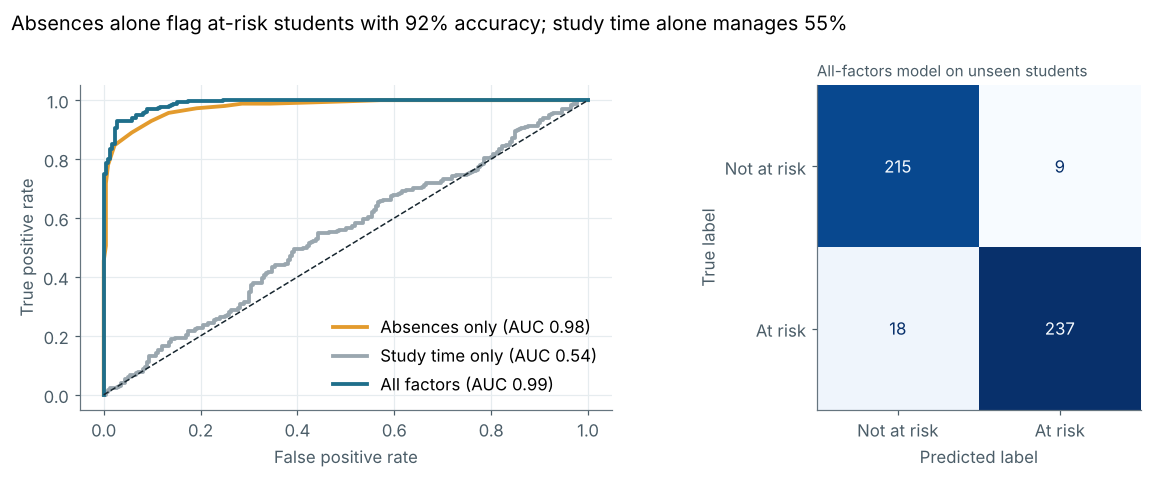

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))
colors = {"All factors": TEAL, "Absences only": AMBER, "Study time only": GREY}
for name, (prob, _) in probs.items():
    fpr, tpr, _ = roc_curve(yte, prob)
    ax1.plot(fpr, tpr, color=colors[name], lw=2.5, label=f"{name} (AUC {roc_auc_score(yte, prob):.2f})")
ax1.plot([0, 1], [0, 1], color=INK, lw=1, ls="--")
ax1.set_xlabel("False positive rate"); ax1.set_ylabel("True positive rate")
ax1.legend(frameon=False, loc="lower right")
ConfusionMatrixDisplay.from_predictions(
    yte, probs["All factors"][1], display_labels=["Not at risk", "At risk"], colorbar=False, ax=ax2, cmap="Blues")
ax2.grid(False)
ax2.set_title("All-factors model on unseen students", loc="left", fontsize=10, color="#4b5d68")
acc_abs = risk_results.loc["Logistic regression: Absences only", "Accuracy"]
acc_study = risk_results.loc["Logistic regression: Study time only", "Accuracy"]
fig.suptitle(f"Absences alone flag at-risk students with {acc_abs:.0%} accuracy; study time alone manages {acc_study:.0%}",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "08_at_risk_model.png")
plt.show()

## 8. Findings, caveats and next steps

### Answers to the original questions

1. **Does more study time mean a higher GPA?** Yes, but the effect is modest. Each extra weekly hour is associated with about +0.029 GPA (95% interval 0.023-0.035). The top study-time quartile averages 0.41 GPA points more than the bottom quartile (Cohen's d = 0.46), and study time on its own explains only about 3% of GPA variation. The estimate barely changes after adjusting for the other factors.
2. **Does better attendance mean a higher GPA?** Yes, and by a wide margin. Each absence is associated with about -0.10 GPA (r = -0.92), so five extra absences cost roughly half a GPA point. Absences alone explain about 85% of GPA variation.

### What else matters

With absences and study time held fixed, tutoring (+0.25), parental support (+0.15 per level), extracurriculars (+0.19) and sports (+0.19) each add to GPA, while age, gender and parental education show no clear effect. Extracurriculars and sports look nearly irrelevant in a simple correlation (r below 0.10) because absences swamp everything else; they only show up once absences are accounted for.

### How well can GPA be predicted?

A plain linear regression is the best model, with a test RMSE of 0.20 GPA points and R-squared of 0.95 on students it never saw. Random forest and gradient boosting did not beat it, which suggests the relationships are close to linear. For an early-warning flag, absences alone identify students below a 2.0 GPA with 92% accuracy, and adding the other factors lifts that to 94% (precision 96%, recall 93%).

### If the relationships are causal, what would they imply?

An attendance intervention would likely pay off more than urging students to study more hours: one fewer absence is worth about as much GPA as three and a half extra weekly study hours. That conclusion depends on absences being a cause of low grades rather than a symptom of something else (illness, disengagement, home circumstances), which this data cannot tell us.

### Caveats

- **The data looks synthetic.** The predictors are almost perfectly uncorrelated with each other, study time and absences are close to uniform, and a model explains 95% of GPA variation, far more than is typical for real student records. Treat the results as a demonstration of method on this dataset, not as evidence about real students.
- **Association, not causation.** This is observational data; nothing here proves that changing study time or attendance would change GPA.
- **`GradeClass` is not fully consistent with `GPA`** (93% agreement), so it was excluded from every model to avoid leakage.
- **Ordinal scores are treated as numbers.** `ParentalSupport` and `ParentalEducation` (0-4) enter the models as numeric scales, which assumes equal steps between levels.
- **The 53% at-risk rate is high,** because the average GPA in this data is 1.9. A real school would choose its threshold differently.

### Next steps

- Re-run the analysis on real, non-synthetic school data and compare effect sizes.
- Test interactions (for example, does tutoring help more for students with many absences?) and recode ordinal scores as categories.
- Add a time dimension (term-by-term GPA and attendance) so the early-warning flag can use only information available before grades are final.
- Turn the at-risk model into a simple dashboard for advisers.